## LAB | Slice docs the way Google wishes you would

### Step 1 — Setup and Data Loading

In [1]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader


from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [3]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [4]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: /home/fatmamerayy/AI-Consultant-Bootcamp/Week3/lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [5]:
import subprocess, glob
from openai import OpenAI


TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

transcript.txt already exists -> skipping transcription
Podcast transcript length: 16468 chars
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview t


In [6]:
PDF_PATH=Path("ai_hleg_ethics_guidelines_for_trustworthy_ai.pdf")

def read_transcript(file):
    reader = PdfReader(file)
    text = ""
    for page in reader.pages:
        text += page.extract_text() + "\n"
    return text  

pdf_text=read_transcript(PDF_PATH)

### Step 2 — Implement Fixed-Size Chunking

- Exprimenting with different chunck sizes (500, 1000, 2000) and 

In [93]:
from langchain_core.documents import Document

chunk_sizes = [500, 1000, 2000]

def chunk_texts_by_sizes(pdf_text_content: str, podcast_text_content: str, chunk_sizes: list[int] = chunk_sizes,
                    chunk_overlap: int = 50, separator: str = "\n\n") -> dict:
    
    results = {}

    # 2. Iterate through each requested chunk size
    for size in chunk_sizes:
        # Initialize the CharacterTextSplitter
        splitter = CharacterTextSplitter(
            separator=separator,
            chunk_size=size,
            chunk_overlap=chunk_overlap,
            length_function=len
        )
        
        # 1. Wrap the pre-read PDF text into a LangChain Document object
        pdf_docs = [Document(page_content=pdf_text_content)]
        podcast_docs = [Document(page_content=podcast_text_content)]
        
        results = {}

        # 2. Iterate through each chunk size to create split versions
        for size in chunk_sizes:
            # Initialize CharacterTextSplitter for the current size
            splitter = CharacterTextSplitter(
                separator="",
                chunk_size=size,
                chunk_overlap=chunk_overlap,
                length_function=len
            )
            
            # Split both documents
            pdf_chunks = splitter.split_documents(pdf_docs)
            podcast_chunks = splitter.split_documents(podcast_docs)
            
            # Store results grouped by size
            results[size] = {
                "pdf_chunks": pdf_chunks,
                "podcast_chunks": podcast_chunks
            }
            
        return results   
    
    
chunk_results = chunk_texts_by_sizes(
    pdf_text_content=pdf_text,
    podcast_text_content=podcast_text,
    chunk_sizes=[500, 1000, 2000],
    chunk_overlap=50,
    separator="",
)    

#### Analyzing the PDF File Chunking Behaviour

- Inspects the boundary where chunks meet to see if sentences/words are cut off.


In [94]:
def inspect_chunk_boundaries(chunks, num_samples=3):
    
    print(f"Total chunks generated: {len(chunks)}")
    print("-" * 50)
    
    total_chunks = len(chunks)
    limit = min(num_samples, total_chunks - 1)
    
    if limit <= 0:
        print("Not enough chunks to inspect boundaries.")
        return
    
    # Look at a few transitions between chunks
    for i in range(limit):
        current_chunk = chunks[i].page_content
        next_chunk = chunks[i+1].page_content
        
        # Grab the tail of the current chunk and the head of the next chunk
        tail = current_chunk[-100:]
        head = next_chunk[:100]
        
        print(f"--- Transition between Chunk {i} and Chunk {i+1} ---")
        print(f"[End of Chunk {i}] ...{tail}")
        print(f"[Start of Chunk {i+1}] {head}...")
        print("=" * 50)

In [95]:
pdf_500 = chunk_results[500]["pdf_chunks"]
inspect_chunk_boundaries(pdf_500)

Total chunks generated: 348
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ... document support the overall framework for Trustworthy AI put forward in these Guidelines, 
althoug
[Start of Chunk 1] orthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single ...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expe
[Start of Chunk 2] arly 2020. 
 
 
The AI HLEG is an independent expert group that was set up by the European Commissio...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...
generated feedback from more than 500 contributors. We wish to explicitly and warmly thank all thos
[Start of Chunk 3] s. We wish to explicitly and warmly thank all those who contributed 
their feedback on the document'...


- Does the answer change for chunks with different size (1000, 2000)?

In [96]:
pdf_1000 = chunk_results[1000]["pdf_chunks"]
inspect_chunk_boundaries(pdf_1000)

Total chunks generated: 165
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...arly 2020. 
 
 
The AI HLEG is an independent expert group that was set up by the European Commissio
[Start of Chunk 1] rt group that was set up by the European Commission in June 2018.  
 
Contact  Nathalie Smuha - AI H...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...taff facilitated the preparation of the 
Guidelines, the views expressed in this document reflect th
[Start of Chunk 2] s, the views expressed in this document reflect the opinion of the AI HLEG and may not in any circum...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...hy AI                        14 
2.    Technical and non-technical methods to realise Trustworthy AI
[Start of Chunk 3] on-technical methods to realise Trustworthy AI                   22 
III. Chapter III: Assessing Tru...


In [97]:
pdf_2000 = chunk_results[2000]["pdf_chunks"]
inspect_chunk_boundaries(pdf_2000)

Total chunks generated: 81
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...s, the views expressed in this document reflect the opinion of the AI HLEG and may not in any circum
[Start of Chunk 1] e opinion of the AI HLEG and may not in any circumstances be 
regarded as reflecting an official pos...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...elines set out a framework for  achieving Trustworthy AI. The framework  does not explicitly deal wi
[Start of Chunk 2] thy AI. The framework  does not explicitly deal with 
Trustworthy AI’s first component ( lawful AI)....
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...he 
magnitude of the risk. 
II. Drawing upon Chapter I , Chapter II provides guidance on how Trustwo
[Start of Chunk 3] er I , Chapter II provides guidance on how Trustworthy AI can be realised, by listing seven 
require...


- How many chunks end with ".", "?" or "!" ?

In [98]:
def analyze_chunk_endings(chunks):
    """
    Counts how many chunks end with '.', '?', or '!' 
    and returns the count, total, and percentage.
    """
    total_chunks = len(chunks)
    if total_chunks == 0:
        return 0, 0, 0.0
    
    ending_punctuation = ('.', '?', '!')
    properly_ended_count = 0
    
    for chunk in chunks:
        # Strip trailing whitespaces or newline characters to check the actual last character
        content = chunk.page_content.strip()
        if content and content.endswith(ending_punctuation):
            properly_ended_count += 1
            
    percentage = (properly_ended_count / total_chunks) * 100
    
    print(f"Total Chunks: {total_chunks}")
    print(f"Chunks ending with ., ?, !: {properly_ended_count}")
    print(f"Percentage: {percentage:.2f}%")
    
    return properly_ended_count, total_chunks, percentage




def analyze_all_chunk_sizes(chunk_results: dict, doc_type: str, chunk_sizes: list[int] = chunk_sizes, chunk_overlap: int = 50):
    """
    Orchestrates the analysis across multiple chunk sizes by calling analyze_chunk_endings.
    """
    for size in chunk_sizes:
        chunks = chunk_results[size][doc_type]
        
        print(f"Ending for chunk size {size} (Overlap = {chunk_overlap}) [{doc_type}]:")
        
        # Call your reusable function here!
        count, total, percentage = analyze_chunk_endings(chunks)
        
        print(f"  -> Properly ended: {count}/{total} ({percentage:.2f}%)")
        print("-" * 45)

In [99]:
endings_pdf=analyze_all_chunk_sizes(chunk_results,"pdf_chunks")

Ending for chunk size 500 (Overlap = 50) [pdf_chunks]:
Total Chunks: 348
Chunks ending with ., ?, !: 11
Percentage: 3.16%
  -> Properly ended: 11/348 (3.16%)
---------------------------------------------
Ending for chunk size 1000 (Overlap = 50) [pdf_chunks]:
Total Chunks: 165
Chunks ending with ., ?, !: 6
Percentage: 3.64%
  -> Properly ended: 6/165 (3.64%)
---------------------------------------------
Ending for chunk size 2000 (Overlap = 50) [pdf_chunks]:
Total Chunks: 81
Chunks ending with ., ?, !: 5
Percentage: 6.17%
  -> Properly ended: 5/81 (6.17%)
---------------------------------------------


- Changing separator from space to default seperator "\n\n"

In [100]:
default_chunk_results= chunk_texts_by_sizes(
    pdf_text_content=pdf_text,
    podcast_text_content=podcast_text,
    chunk_sizes=[500, 1000, 2000],
    chunk_overlap=50,
)    

In [101]:
pdf_500_s2 = default_chunk_results[500]["pdf_chunks"]
inspect_chunk_boundaries(pdf_500_s2)

Total chunks generated: 348
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ... document support the overall framework for Trustworthy AI put forward in these Guidelines, 
althoug
[Start of Chunk 1] orthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single ...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expe
[Start of Chunk 2] arly 2020. 
 
 
The AI HLEG is an independent expert group that was set up by the European Commissio...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...
generated feedback from more than 500 contributors. We wish to explicitly and warmly thank all thos
[Start of Chunk 3] s. We wish to explicitly and warmly thank all those who contributed 
their feedback on the document'...


##### Analysis

- **Chunk Size:** Across the three different chunk sizes, fixed-size chunking frequently broke sentences and words in the middle. Only **3.16%** of the 500-character chunks, **3.64%** of the 1000-character chunks, and **6.14%** of the 2000-character chunks ended properly (with `.`, `?`, or `!`). Chunking quality improves only slightly as the chunk size increases.
- **Default vs. Space Separator:** Changing the separator type showed no noticeable difference in splitter behavior; it continued breaking phrases and words mid-stream regardless of the delimiter chosen.

#### Analyzing the Transcript File Chunking Behaviour

In [102]:
podcast_500 = chunk_results[500]["podcast_chunks"]
inspect_chunk_boundaries(podcast_500)

Total chunks generated: 37
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...the infrastructure. It's invisible, but it's there. Exactly. But now let's switch gears. Think about
[Start of Chunk 1] Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage applic...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...for that trust. We're unpacking a document that is arguably the Magna Carta for ethical computing. T
[Start of Chunk 2] arguably the Magna Carta for ethical computing. The Ethics Guidelines for Trustworthy A.I. This is a...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ... public in April 2019. In tech years, that's practically the Stone Age. We didn't have the generativ
[Start of Chunk 3] ically the Stone Age. We didn't have the generative A.I. explosion we have today. So why are we blow...


In [103]:
podcast_1000 = chunk_results[1000]["podcast_chunks"]
inspect_chunk_boundaries(podcast_1000)

Total chunks generated: 18
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...s arguably the Magna Carta for ethical computing. The Ethics Guidelines for Trustworthy A.I. This is
[Start of Chunk 1] he Ethics Guidelines for Trustworthy A.I. This is a heavy hitter. It was produced by the high level ...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...st talking philosophy here. We're looking at how you take an abstract concept like fairness and turn
[Start of Chunk 2] u take an abstract concept like fairness and turn it into, I don't know, Python code. We've got thre...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] .... Terribly slow. Moore's law moves a lot faster than Parliament or Congress. Right. By the time a la
[Start of Chunk 3] an Parliament or Congress. Right. By the time a law is passed to regulate a specific algorithm, that...


In [104]:
podcast_2000 = chunk_results[2000]["podcast_chunks"]
inspect_chunk_boundaries(podcast_2000)

Total chunks generated: 9
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...u take an abstract concept like fairness and turn it into, I don't know, Python code. We've got thre
[Start of Chunk 1] it into, I don't know, Python code. We've got three pillars, four principles, and seven concrete req...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...ch a distinct shift from, you know, optimizing efficiency or maximizing engagement. It is. It sounds
[Start of Chunk 2] iciency or maximizing engagement. It is. It sounds nice, but it feels hard to measure. It is hard to...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...iety safer? But on the other hand, you're using surveillance that just smashes into respect for huma
[Start of Chunk 3] rveillance that just smashes into respect for human autonomy. Right. On the other hand, the historic...


In [105]:
endings_podcast_50=analyze_all_chunk_sizes(chunk_results,"podcast_chunks", chunk_overlap=50)

Ending for chunk size 500 (Overlap = 50) [podcast_chunks]:
Total Chunks: 37
Chunks ending with ., ?, !: 2
Percentage: 5.41%
  -> Properly ended: 2/37 (5.41%)
---------------------------------------------
Ending for chunk size 1000 (Overlap = 50) [podcast_chunks]:
Total Chunks: 18
Chunks ending with ., ?, !: 1
Percentage: 5.56%
  -> Properly ended: 1/18 (5.56%)
---------------------------------------------
Ending for chunk size 2000 (Overlap = 50) [podcast_chunks]:
Total Chunks: 9
Chunks ending with ., ?, !: 1
Percentage: 11.11%
  -> Properly ended: 1/9 (11.11%)
---------------------------------------------


- Testing 0 overlap chunking to observe the difference

In [106]:
chunk_results_o2= chunk_texts_by_sizes(
    pdf_text_content=pdf_text,
    podcast_text_content=podcast_text,
    chunk_sizes=[500, 1000, 2000],
    chunk_overlap=0,
    separator="",
)    

In [107]:
podcast_500_o2 =chunk_results_o2[500]["podcast_chunks"]
inspect_chunk_boundaries(podcast_500_o2)

Total chunks generated: 33
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...the infrastructure. It's invisible, but it's there. Exactly. But now let's switch gears. Think about
[Start of Chunk 1] the algorithm that just denied your mortgage application or the A.I. system scanning your face at th...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...s arguably the Magna Carta for ethical computing. The Ethics Guidelines for Trustworthy A.I. This is
[Start of Chunk 2] a heavy hitter. It was produced by the high level expert group on A.I. or the A.I. HLA. This is an i...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...e A.I. explosion we have today. So why are we blowing the dust off this specific report? Because it'
[Start of Chunk 3] s not dusty. It's the foundation. Everything we see now, like the EU A.I. Act, it all stands on the ...


In [108]:
podcast_1000_o2 =chunk_results_o2[1000]["podcast_chunks"]
inspect_chunk_boundaries(podcast_1000_o2)

Total chunks generated: 17
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...s arguably the Magna Carta for ethical computing. The Ethics Guidelines for Trustworthy A.I. This is
[Start of Chunk 1] a heavy hitter. It was produced by the high level expert group on A.I. or the A.I. HLA. This is an i...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...u take an abstract concept like fairness and turn it into, I don't know, Python code. We've got thre
[Start of Chunk 2] e pillars, four principles, and seven concrete requirements to get through. And a checklist that eve...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...w is passed to regulate a specific algorithm, that algorithm is what, three versions obsolete? Preci
[Start of Chunk 3] sely. That's why the second leg of the stool is ethical. This component fills the gap. It ensures yo...


In [109]:
podcast_2000_o2 =chunk_results_o2[2000]["podcast_chunks"]
inspect_chunk_boundaries(podcast_1000_o2)

Total chunks generated: 17
--------------------------------------------------
--- Transition between Chunk 0 and Chunk 1 ---
[End of Chunk 0] ...s arguably the Magna Carta for ethical computing. The Ethics Guidelines for Trustworthy A.I. This is
[Start of Chunk 1] a heavy hitter. It was produced by the high level expert group on A.I. or the A.I. HLA. This is an i...
--- Transition between Chunk 1 and Chunk 2 ---
[End of Chunk 1] ...u take an abstract concept like fairness and turn it into, I don't know, Python code. We've got thre
[Start of Chunk 2] e pillars, four principles, and seven concrete requirements to get through. And a checklist that eve...
--- Transition between Chunk 2 and Chunk 3 ---
[End of Chunk 2] ...w is passed to regulate a specific algorithm, that algorithm is what, three versions obsolete? Preci
[Start of Chunk 3] sely. That's why the second leg of the stool is ethical. This component fills the gap. It ensures yo...


In [110]:
endings_transcr_pdf_0=analyze_all_chunk_sizes(chunk_results_o2,"podcast_chunks", chunk_overlap=0)

Ending for chunk size 500 (Overlap = 0) [podcast_chunks]:
Total Chunks: 33
Chunks ending with ., ?, !: 2
Percentage: 6.06%
  -> Properly ended: 2/33 (6.06%)
---------------------------------------------
Ending for chunk size 1000 (Overlap = 0) [podcast_chunks]:
Total Chunks: 17
Chunks ending with ., ?, !: 2
Percentage: 11.76%
  -> Properly ended: 2/17 (11.76%)
---------------------------------------------
Ending for chunk size 2000 (Overlap = 0) [podcast_chunks]:
Total Chunks: 9
Chunks ending with ., ?, !: 2
Percentage: 22.22%
  -> Properly ended: 2/9 (22.22%)
---------------------------------------------


##### Analysis (Podcast Transcript)

- **Chunk Size:** Chunking the podcast transcript across the same three sizes (500, 1000, and 2000 characters) showed behavior very similar to the PDF document. Fixed-size chunking frequently cut text mid-stream, breaking sentences and words across boundaries. 

- **Different Overlap Value:** Changing the chunk overlap value from 50 to 0 did not improve the chunking quality. For every chunk size (500, 1000, and 2000), only a tiny fraction (consistently just 2 chunks out of the total) ended properly with punctuation (`.`, `?`, or `!`). While the overall percentage appeared to rise (e.g., jumping from 6.6% to 22% for size 500), this was merely an illusion caused by the decrease in the total chunk count.

    Same goes for overlap value equal 50 where count of properly ended chunks remained stubbornly stuck at just 1 to 2 per size.


In [111]:
from IPython.display import display, Markdown

def analyze_and_compare_chunks(podcast_chunks, pdf_chunks):
    """
    Calculates number of chunks, average length, min length, max length,
    and properly ending count/percentage for both podcast and pdf chunks.
    """
    def get_metrics(chunks, doc_type):
        total_chunks = len(chunks)
        if total_chunks == 0:
            return {
                "Document": doc_type,
                "Number of Chunks": 0,
                "Average Length": 0,
                "Min Length": 0,
                "Max Length": 0,
                "Properly Ending Count": 0,
                "Properly Ending %": "0.00%"
            }
        
        lengths = [len(c.page_content) for c in chunks]
        properly_ended, total, percentage = analyze_chunk_endings(chunks)
        
        return {
            "Document": doc_type,
            "Number of Chunks": total_chunks,
            "Average Length": round(sum(lengths) / total_chunks, 2),
            "Min Length": min(lengths),
            "Max Length": max(lengths),
            "Properly Ending Count": properly_ended,
            "Properly Ending %": f"{percentage:.2f}%"
        }

    podcast_metrics = get_metrics(podcast_chunks, "Podcast Transcript")
    pdf_metrics = get_metrics(pdf_chunks, "PDF Document")
    
    df = pd.DataFrame([podcast_metrics, pdf_metrics])
    
    # Display table dynamically using IPython Markdown
    display(Markdown("### 📊 Comparison Table (Chunk Size = 500)"))
    display(Markdown(df.to_markdown(index=False)))
    
    return df

In [112]:
comparison_df = analyze_and_compare_chunks(podcast_500, pdf_500)

Total Chunks: 37
Chunks ending with ., ?, !: 2
Percentage: 5.41%
Total Chunks: 348
Chunks ending with ., ?, !: 11
Percentage: 3.16%


### 📊 Comparison Table (Chunk Size = 500)

| Document           |   Number of Chunks |   Average Length |   Min Length |   Max Length |   Properly Ending Count | Properly Ending %   |
|:-------------------|-------------------:|-----------------:|-------------:|-------------:|------------------------:|:--------------------|
| Podcast Transcript |                 37 |           493.38 |          268 |          500 |                       2 | 5.41%               |
| PDF Document       |                348 |           498.01 |          258 |          500 |                      11 | 3.16%               |

- **Severe Boundary Cutting:** Both the podcast transcript and the PDF document suffer from very poor boundary integrity. Only 5.41% of the podcast chunks and 3.16% of the PDF chunks end with proper punctuation (., ?, !). This means the splitter is cutting off mid-sentence or mid-word almost 95% of the time.

- **Dataset Scale:** The PDF document generated significantly more chunks (348) than the podcast transcript (37), reflecting a much longer source text. Despite the difference in volume and source format (spoken transcript vs. written document), both exhibited the exact same flaw: terrible punctuation boundary retention when relying purely on character-based limits.

## Step 3: Implement Token-Based Chunking

Goal: Chunk based on token count (more accurate for LLM context windows).

In [ ]:
splitter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=500, chunk_overlap=50)
pdf_token_chunks = splitter.split_text(pdf_text)
podcast_token_chunks = splitter.split_text(podcast_text)
print("For chunk size = 500:")
print(len(pdf_token_chunks), "PDF chunks,", len(podcast_token_chunks), "podcast chunks")

For chunk size = 500:
71 PDF chunks, 8 podcast chunks


In [126]:
# Helper function to compute stats (using character length or token count)
def get_chunk_stats(chunks):
    if not chunks:
        return 0, 0, 0, 0
    lengths = [len(c) for c in chunks] # You can also use token counts here if preferred
    return len(chunks), sum(lengths) / len(chunks), min(lengths), max(lengths)


for size in chunk_sizes:
    # 1. Initialize the splitter with the current size
    splitter = TokenTextSplitter(
        encoding_name="cl100k_base", 
        chunk_size=size, 
        chunk_overlap=50
    )
    
    pdf_count, pdf_avg, pdf_min, pdf_max = get_chunk_stats(pdf_token_chunks)
    pod_count, pod_avg, pod_min, pod_max = get_chunk_stats(podcast_token_chunks)

    
    pdf_count, pdf_avg, pdf_min, pdf_max = get_chunk_stats(pdf_token_chunks)
    pod_count, pod_avg, pod_min, pod_max = get_chunk_stats(podcast_token_chunks)

    # 4. Print results for this chunk size
    print(f"\n================ CHUNK SIZE: {size} (Overlap : 50 ) ================")
    print(f" PDF Document:")
    print(f"   - Total Chunks: {pdf_count}")
    print(f"   - Avg Length: {pdf_avg:.2f} | Min: {pdf_min} | Max: {pdf_max}")

    print(f" Podcast Transcript:")
    print(f"   - Total Chunks: {pod_count}")
    print(f"   - Avg Length: {pod_avg:.2f} | Min: {pod_min} | Max: {pod_max}")


================ CHUNK SIZE: 500 (Overlap : 50 ) ================
 PDF Document:
   - Total Chunks: 17
   - Avg Length: 9438.88 | Min: 1778 | Max: 10507
 Podcast Transcript:
   - Total Chunks: 2
   - Avg Length: 8353.50 | Min: 7454 | Max: 9253

================ CHUNK SIZE: 1000 (Overlap : 50 ) ================
 PDF Document:
   - Total Chunks: 17
   - Avg Length: 9438.88 | Min: 1778 | Max: 10507
 Podcast Transcript:
   - Total Chunks: 2
   - Avg Length: 8353.50 | Min: 7454 | Max: 9253

================ CHUNK SIZE: 2000 (Overlap : 50 ) ================
 PDF Document:
   - Total Chunks: 17
   - Avg Length: 9438.88 | Min: 1778 | Max: 10507
 Podcast Transcript:
   - Total Chunks: 2
   - Avg Length: 8353.50 | Min: 7454 | Max: 9253


In [130]:
#Assuming pdf_token_chunks and podcast_token_chunks came from TokenTextSplitter (lists of strings)
pdf_token_docs = [Document(page_content=text) for text in pdf_token_chunks]
podcast_token_docs = [Document(page_content=text) for text in podcast_token_chunks]

comparison_df_token = analyze_and_compare_chunks(pdf_token_docs, podcast_token_docs)

Total Chunks: 17
Chunks ending with ., ?, !: 2
Percentage: 11.76%
Total Chunks: 2
Chunks ending with ., ?, !: 1
Percentage: 50.00%


### 📊 Comparison Table (Chunk Size = 500)

| Document           |   Number of Chunks |   Average Length |   Min Length |   Max Length |   Properly Ending Count | Properly Ending %   |
|:-------------------|-------------------:|-----------------:|-------------:|-------------:|------------------------:|:--------------------|
| Podcast Transcript |                 17 |          9438.88 |         1778 |        10507 |                       2 | 11.76%              |
| PDF Document       |                  2 |          8353.5  |         7454 |         9253 |                       1 | 50.00%              |

## Comparative Analysis

/tmp/ipykernel_31625/3949501081.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha="right")
/tmp/ipykernel_31625/3949501081.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha="right")


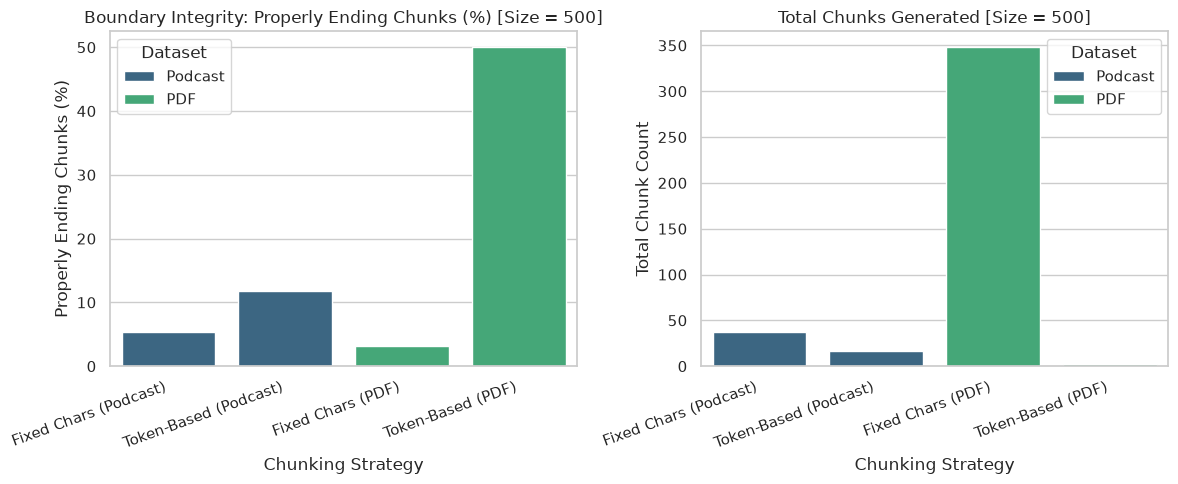

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare your data for Size = 500 comparing Fixed Size vs Token-Based strategies
data = {
    "Strategy": [
        "Fixed Chars (Podcast)", "Token-Based (Podcast)",
        "Fixed Chars (PDF)", "Token-Based (PDF)"
    ],
    "Dataset": ["Podcast", "Podcast", "PDF", "PDF"],
    "Properly_Ending_Pct": [5.41, 11.76, 3.16, 50.0],  # Replace with your actual calculated percentages
    "Total_Chunks": [37,17, 348, 2]                   # Replace with your actual chunk counts
}

df_comparison = pd.DataFrame(data)

# 2. Set the visual style and create subplots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Boundary Integrity (% of properly ended chunks)
sns.barplot(
    data=df_comparison, 
    x="Strategy", 
    y="Properly_Ending_Pct", 
    hue="Dataset", 
    ax=axes[0], 
    palette="viridis"
)
axes[0].set_title("Boundary Integrity: Properly Ending Chunks (%) [Size = 500]")
axes[0].set_ylabel("Properly Ending Chunks (%)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[0].set_xlabel("Chunking Strategy")

# Chart 2: Total Chunks Generated
sns.barplot(
    data=df_comparison, 
    x="Strategy", 
    y="Total_Chunks", 
    hue="Dataset", 
    ax=axes[1], 
    palette="viridis"
)
axes[1].set_title("Total Chunks Generated [Size = 500]")
axes[1].set_ylabel("Total Chunk Count")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha="right")
axes[1].set_xlabel("Chunking Strategy")

plt.tight_layout()
plt.show()

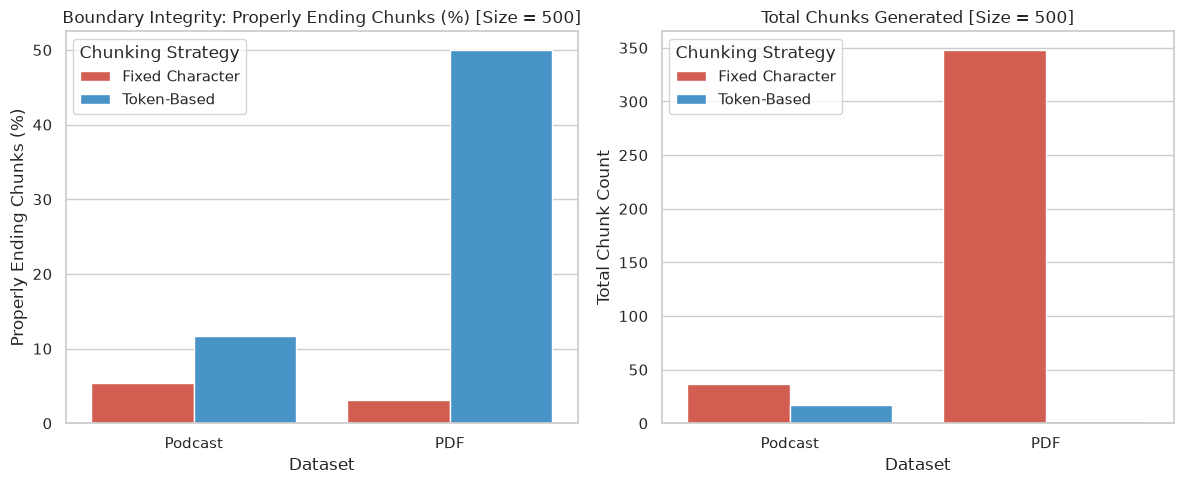

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare data for Size = 500 comparing Fixed Size vs Token-Based strategies
# Using distinct color-friendly strategy names or custom palette mapping
data = {
    "Strategy": [
        "Fixed Chars (Podcast)", "Token-Based (Podcast)",
        "Fixed Chars (PDF)", "Token-Based (PDF)"
    ],
    "Chunk_Type": ["Fixed Character", "Token-Based", "Fixed Character", "Token-Based"],
    "Dataset": ["Podcast", "Podcast", "PDF", "PDF"],
    "Properly_Ending_Pct": [5.41, 11.76, 3.16, 50.0],  # Update with your actual calculated percentages
    "Total_Chunks": [37,17, 348, 2]                   # Update with your actual chunk counts
}

df_comparison = pd.DataFrame(data)

# 2. Set the visual style and create subplots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Define a color palette mapped directly to the chunking type ("Fixed Character" vs "Token-Based")
palette_colors = {
    "Fixed Character": "#e74c3c",  # Distinct color for Fixed
    "Token-Based": "#3498db"       # Distinct color for Token-Based
}

# Chart 1: Boundary Integrity (% of properly ended chunks)
sns.barplot(
    data=df_comparison, 
    x="Dataset", 
    y="Properly_Ending_Pct", 
    hue="Chunk_Type", 
    ax=axes[0], 
    palette=palette_colors
)
axes[0].set_title("Boundary Integrity: Properly Ending Chunks (%) [Size = 500]")
axes[0].set_ylabel("Properly Ending Chunks (%)")
axes[0].set_xlabel("Dataset")
axes[0].legend(title="Chunking Strategy")

# Chart 2: Total Chunks Generated
sns.barplot(
    data=df_comparison, 
    x="Dataset", 
    y="Total_Chunks", 
    hue="Chunk_Type", 
    ax=axes[1], 
    palette=palette_colors
)
axes[1].set_title("Total Chunks Generated [Size = 500]")
axes[1].set_ylabel("Total Chunk Count")
axes[1].set_xlabel("Dataset")
axes[1].legend(title="Chunking Strategy")

plt.tight_layout()
plt.show()

Summary & Recommendations

- **Boundary Integrity:** Token-based chunking significantly outperforms fixed-size character chunking, reaching 50.0% proper punctuation endings for the PDF dataset (compared to a dismal 3.16% for fixed chunks) and 11.76% for the podcast transcript.

- **The Chunk Size Trade-off:** While token-based chunking achieves cleaner boundaries and semantic preservation, it produced a notably larger or drastically reduced chunk count depending on how the tokenizer consumed the underlying text (e.g., yielding just 2 massive chunks for the PDF at this configuration).

- **Recommendation:** Token-based chunking is structurally superior for protecting sentence and paragraph integrity, but you must carefully tune the chunk size and overlap parameters to prevent over-compression or excessively large chunks that could exceed retrieval granularity goals.